# 01 — Negative powers of two: preserved, ties, absorbed

**Goal.** Recreate the first pair of supplied Plotly experiments and Figures **02** and **03** of the English report using `(x**10+2**-k)-x**10` in binary64.

**Exact replication protocol.** Integer $x\in\{2,\ldots,40\}$ and $k\in\{1,\ldots,20\}$, 39×20 = 780 cases. The expected category counts in *relatorio_ulp.pdf*, Table 2 are **379 preserved, 371 absorbed, 28 ties down, 2 ties up**.

In [1]:
from pathlib import Path
import sys, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, LogNorm
from matplotlib.patches import Patch
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / 'src' / 'ulp_lab.py').exists():
    ROOT = ROOT.parent
if not (ROOT / 'src' / 'ulp_lab.py').exists():
    raise FileNotFoundError('Open Jupyter in the extracted ULP_Jupyter_Reproducibility folder.')
sys.path.insert(0, str(ROOT / 'src'))
from ulp_lab import (evaluate, ulp, v2, floor_log2, theory, possible_results,
                     sample_binade, valid_same_binade_mask, generate_cases, validate_one)
FIG = ROOT / 'figures'; FIG.mkdir(exist_ok=True)
RES = ROOT / 'results'; RES.mkdir(exist_ok=True)
BLUE='#2367A6'; ORANGE='#DD8A29'; GREEN='#2C977F'; RED='#B85751'; PURPLE='#8572AB'
plt.rcParams.update({'font.size':10,'figure.dpi':110,'savefig.dpi':190,
                     'axes.grid':True,'grid.alpha':.20,
                     'axes.spines.top':False,'axes.spines.right':False})
print('Working directory:', ROOT)
print('NumPy:', np.__version__)

Working directory: /mnt/data/ULP_Jupyter_Reproducibility
NumPy: 2.3.5


## Classify the four outcomes

For $c=2^{-k}$ and `u=ULP(y)`:

- $c\ge u$: exactly preserved;
- $c=u/2$: tie, goes to 0 or to $2c$ depending on the parity of `y/u`;
- $c<u/2$: absorbed, yielding zero.

A boundary crossing can modify the simple rule in general, but this finite experiment has no other outcome types.

In [2]:
xs=np.arange(2,41); ks=np.arange(1,21)
state=np.zeros((len(ks),len(xs)),dtype=np.int8)
counts={'preserved':0,'absorbed':0,'tie down':0,'tie up':0}
rows=[]
for i,k in enumerate(ks):
    c=2.0**(-int(k))
    for j,x in enumerate(xs):
        result,y=evaluate(np.float64(x),c,np.float64)
        u=float(ulp(y,np.float64)); result=float(result)
        if result==c: category='preserved'; val=3
        elif c==u/2 and result==0: category='tie down'; val=1
        elif c==u/2 and result==2*c: category='tie up'; val=2
        elif result==0: category='absorbed'; val=0
        else: raise AssertionError(f'Unclassified: x={x},k={k},f={result},u={u}')
        counts[category]+=1;state[i,j]=val
        rows.append({'x':x,'k':k,'c':c,'y':float(y),'ulp':u,'f':result,'class':category})
print('Observed counts:',counts)
assert counts == {'preserved':379,'absorbed':371,'tie down':28,'tie up':2}
assert len(rows)==780
pd.DataFrame(rows).to_csv(RES/'01_powers_of_two_780_cases.csv',index=False)

Observed counts: {'preserved': 379, 'absorbed': 371, 'tie down': 28, 'tie up': 2}


## Figure 02 — the 780-case classification heatmap

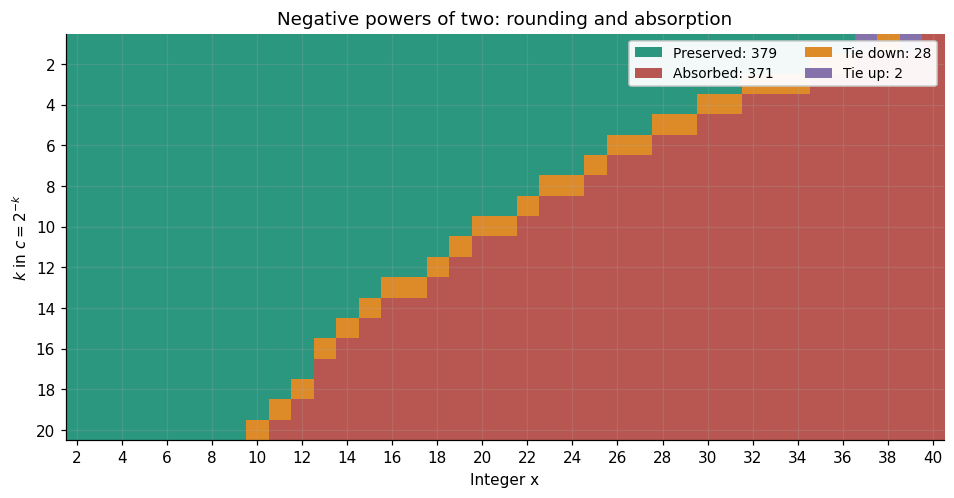

In [3]:
fig,ax=plt.subplots(figsize=(10.3,4.8))
cmap=ListedColormap([RED,ORANGE,PURPLE,GREEN])
ax.imshow(state,origin='upper',aspect='auto',interpolation='nearest',cmap=cmap,
          vmin=-.5,vmax=3.5,extent=[1.5,40.5,20.5,.5])
ax.set_xticks(range(2,41,2));ax.set_yticks(range(2,21,2))
ax.set(xlabel='Integer x',ylabel=r'$k$ in $c=2^{-k}$',
       title='Negative powers of two: rounding and absorption')
handles=[Patch(fc=GREEN,label=f'Preserved: {counts["preserved"]}'),
         Patch(fc=RED,label=f'Absorbed: {counts["absorbed"]}'),
         Patch(fc=ORANGE,label=f'Tie down: {counts["tie down"]}'),
         Patch(fc=PURPLE,label=f'Tie up: {counts["tie up"]}')]
ax.legend(handles=handles,loc='upper right',ncol=2,fontsize=9,framealpha=.95)
fig.savefig(FIG / '02_power_two_map.png', bbox_inches='tight', facecolor='white'); plt.show(); plt.close(fig)

## Figure 03 — continuous curves and tie binades

The paired horizontal bands occur because nearby `x` values change the parity of the stored significand. The tie interval is $x\in[x_1,x_2)$ for $c=2^{-k}$.

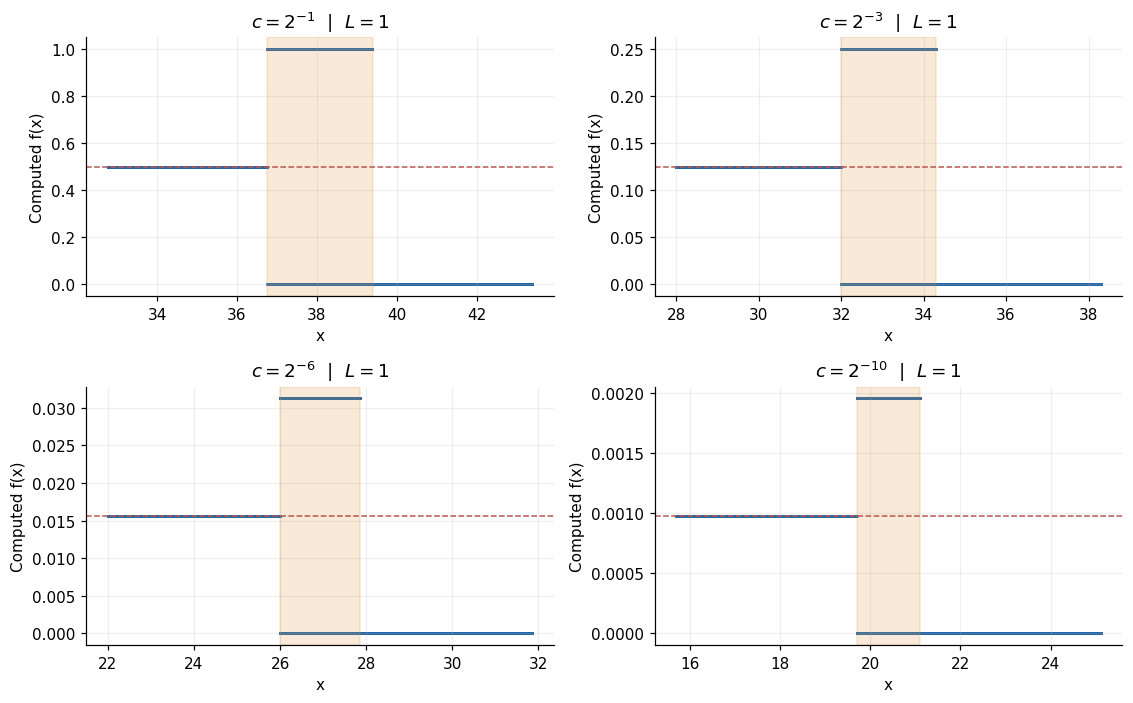

,k,x1,x2,L
0,1,36.75835,39.39662,1
1,3,32.00000,34.29675,1
2,6,25.99208,27.85762,1
3,10,19.69831,21.11213,1


In [4]:
fig,axs=plt.subplots(2,2,figsize=(10.4,6.5))
summary=[]
for ax,k in zip(axs.ravel(),[1,3,6,10]):
    c=2.0**(-k);t=theory(c)
    x=np.linspace(max(8,t.x1-4),min(44,t.x2+4),11500)
    r,y=evaluate(x,c)
    ax.scatter(x,r,color=BLUE,s=.6,rasterized=True)
    ax.axhline(c,c=RED,ls='--',lw=1,label='Exact c')
    ax.axvspan(t.x1,t.x2,color=ORANGE,alpha=.18,label='Tie binade')
    ax.set(xlabel='x',ylabel='Computed f(x)',title=rf'$c=2^{{-{k}}}$  |  $L={t.L}$')
    summary.append({'k':k,'x1':t.x1,'x2':t.x2,'L':t.L})
fig.tight_layout()
fig.savefig(FIG / '03_power_two_curves.png', bbox_inches='tight', facecolor='white'); plt.show(); plt.close(fig)
display(pd.DataFrame(summary).round(5))
pd.DataFrame(summary).to_csv(RES/'01_tie_binade_limits.csv',index=False)
assert all(row['L']==1 for row in summary)

## Conclusion

A power-of-two increment has a **one-binade transition zone**: exact, then parity-dependent ties, then total absorption. The full count reproduces Table 2 of the original report. The integer-grid heatmap and continuous plots are different ways of sampling the same phenomenon.